# Problem 2 — Hierarchical clustering và so sánh K-means

**Câu hỏi:** bốn linkage và $K$ thay đổi cụm như thế nào? Dendrogram cắt ở đâu? Nhạy cảm với outlier và chi phí ra sao?

**Quy tắc chọn trước:** Euclidean cho cả bốn linkage (Ward bắt buộc Euclidean); silhouette cao, ngưỡng cụm tối thiểu 1%, tie band 0.01, ưu tiên $K$ nhỏ hơn rồi DB thấp hơn. Nhãn thật chỉ dùng hậu kiểm sau quyết định cuối.

## Dữ liệu và thiết kế thực nghiệm

[Rice Cammeo/Osmancik (UCI)](https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik), 3.810 hàng, 7 đặc trưng số; DOI [10.24432/C5MW4Z](https://doi.org/10.24432/C5MW4Z), CC BY 4.0. `Class` không tham gia phân cụm/chọn mô hình. Vì đây là bài toán không giám sát trên toàn bộ dữ liệu, scaler được fit trên cùng 3.810 quan sát; không chia train/test theo nhãn. Silhouette dùng cùng 1.000 index ngẫu nhiên cố định cho mọi cấu hình nhằm hạn chế chi phí khoảng cách; các metric khác dùng toàn bộ dữ liệu. Inertia chỉ so sánh trong cùng một không gian raw hoặc scaled.

In [1]:
from __future__ import annotations
from hashlib import sha256
from pathlib import Path
from time import perf_counter
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display, Markdown
from scipy.io import arff
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler

SEED = 42
HASH = '1af97883100c89de2ea2972f7a28d428f4f1c14711a61defc0b0569e9eb65665'
NAMES = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
KS = range(2, 11)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True})
print('Versions:', np.__version__, pd.__version__, scipy.__version__, sklearn.__version__)

Versions: 2.4.6 3.0.3 1.17.1 1.8.0


Data: data\Rice_Cammeo_Osmancik.arff shape: (3810, 7) missing: 0 duplicates: 0 SHA-256: 1af97883100c89de2ea2972f7a28d428f4f1c14711a61defc0b0569e9eb65665


,dtype
Area,float64
Perimeter,float64
Major_Axis_Length,float64
Minor_Axis_Length,float64
Eccentricity,float64
Convex_Area,float64
Extent,float64


,min,50%,mean,std,max
Area,7551.000,12421.500,12667.728,1732.368,18913.000
Perimeter,359.100,448.852,454.239,35.597,548.446
Major_Axis_Length,145.264,185.810,188.776,17.449,239.010
Minor_Axis_Length,59.532,86.435,86.314,5.730,107.542
Eccentricity,0.777,0.889,0.887,0.021,0.948
Convex_Area,7723.000,12706.500,12952.497,1776.972,19099.000
Extent,0.497,0.645,0.662,0.077,0.861


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
Area,1.00,0.97,0.90,0.79,0.35,1.00,-0.06
Perimeter,0.97,1.00,0.97,0.63,0.54,0.97,-0.13
Major_Axis_Length,0.90,0.97,1.00,0.45,0.71,0.90,-0.14
Minor_Axis_Length,0.79,0.63,0.45,1.00,-0.29,0.79,0.06
Eccentricity,0.35,0.54,0.71,-0.29,1.00,0.35,-0.20
Convex_Area,1.00,0.97,0.90,0.79,0.35,1.00,-0.07
Extent,-0.06,-0.13,-0.14,0.06,-0.20,-0.07,1.00


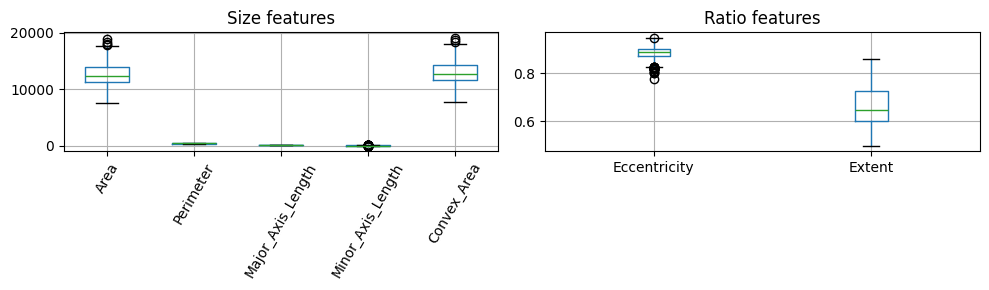

In [2]:
def data_path() -> Path:
    for path in [Path('data/Rice_Cammeo_Osmancik.arff'), Path('unsupervised-learning/data/Rice_Cammeo_Osmancik.arff')]:
        if path.is_file():
            return path
    raise FileNotFoundError('Rice ARFF not found; see README.md')

path = data_path()
assert sha256(path.read_bytes()).hexdigest() == HASH, 'Data checksum mismatch'
records, _ = arff.loadarff(path)
frame = pd.DataFrame(records)
y_true = frame['Class'].str.decode('ascii').to_numpy()
features = frame[NAMES].astype(float)
assert features.shape == (3810, 7) and features.index.is_unique
assert np.isfinite(features.to_numpy()).all()
print('Data:', path, 'shape:', features.shape, 'missing:', features.isna().sum().sum(),
      'duplicates:', features.duplicated().sum(), 'SHA-256:', HASH)
display(features.dtypes.rename('dtype').to_frame())
display(features.describe().T[['min', '50%', 'mean', 'std', 'max']].round(3))
display(features.corr().round(2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
features[['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Convex_Area']].boxplot(ax=ax[0], rot=60)
features[['Eccentricity', 'Extent']].boxplot(ax=ax[1])
ax[0].set_title('Size features'); ax[1].set_title('Ratio features')
plt.tight_layout(); plt.show()

**Cách đọc output dữ liệu:** `min`/`max` cho biết miền giá trị, `50%` là median, còn `std` đo mức phân tán quanh mean. `Area` và `Convex_Area` gần như tương quan hoàn hảo ($r\approx1$); `Perimeter` cũng tương quan mạnh với hai biến này. Vì vậy khoảng cách raw không chỉ ưu tiên nhóm đặc trưng kích thước do trị số lớn, mà còn có thể **đếm lặp** cùng tín hiệu kích thước qua nhiều chiều tương quan. `Eccentricity` và `Extent` nằm trên thang tỷ lệ nhỏ hơn nên đóng góp rất ít vào Euclidean raw.

Boxplot cho thấy miền số của hai nhóm đặc trưng khác nhau rõ rệt, nhưng điểm nằm ngoài whisker chưa mặc nhiên là lỗi: đây có thể là hạt thật có hình thái cực trị. Vì thế notebook giữ nguyên toàn bộ hàng, so sánh raw với chuẩn hóa, rồi kiểm tra độ nhạy outlier riêng. Không có missing/infinite/duplicate giúp loại trừ ba nguyên nhân kỹ thuật thường làm sai khoảng cách, nhưng không chứng minh mọi phép đo đều sạch nhiễu.

In [3]:
X_raw = features.to_numpy(copy=True)
X_scaled = StandardScaler().fit_transform(X_raw)
matrices = {'raw': X_raw, 'scaled': X_scaled}
sample_idx = np.sort(np.random.default_rng(SEED).choice(len(X_raw), 1000, replace=False))
assert len(np.unique(sample_idx)) == 1000

def sizes(labels: np.ndarray) -> str:
    return ', '.join(map(str, np.bincount(labels)))

def quality(X: np.ndarray, labels: np.ndarray) -> dict[str, float]:
    if len(np.unique(labels[sample_idx])) < 2:
        raise ValueError('Sample has fewer than two clusters')
    return {'silhouette': silhouette_score(X[sample_idx], labels[sample_idx]),
            'ch': calinski_harabasz_score(X, labels),
            'db': davies_bouldin_score(X, labels)}

print('Silhouette sample:', len(sample_idx), 'seed:', SEED)

Silhouette sample: 1000 seed: 42


## 1. Bốn linkage trên cùng dữ liệu

Single dùng cặp gần nhất nên chỉ cần một chuỗi điểm trung gian để nối hai vùng; complete dùng cặp xa nhất nên ép đường kính cụm nhỏ; average dùng trung bình mọi cặp nên ít cực đoan hơn; Ward chọn phép gộp làm tăng tổng bình phương trong cụm ít nhất nên gần tinh thần K-means. Mỗi linkage biểu diễn một định nghĩa khác nhau về “hai cụm gần nhau”, vì vậy cùng dữ liệu có thể cho cây và phân hoạch rất khác. Chạy cả raw và scaled, $K=2..10$.

,scale,linkage,k,silhouette,ch,db,sizes,min_size,runtime_ms
0,raw,single,2,NaN,12.507,0.234,"3809, 1",1,236.716
1,raw,single,3,NaN,18.351,0.292,"3806, 1, 3",1,182.605
2,raw,single,4,NaN,15.831,0.282,"3, 3805, 1, 1",1,151.282
3,raw,single,5,NaN,11.877,0.276,"3805, 2, 1, 1, 1",1,159.989
4,raw,single,6,NaN,13.164,0.279,"3803, 2, 2, 1, 1, 1",1,177.688
...,...,...,...,...,...,...,...,...,...
67,scaled,ward,6,0.183,1518.568,1.372,"917, 1051, 815, 331, 359, 337",331,384.098
68,scaled,ward,7,0.169,1456.379,1.290,"1051, 331, 815, 385, 359, 337, 532",331,378.411
69,scaled,ward,8,0.177,1426.124,1.340,"815, 331, 504, 385, 359, 337, 532, 547",331,399.697
70,scaled,ward,9,0.169,1390.688,1.355,"504, 331, 521, 385, 359, 337, 532, 547, 294",294,373.232


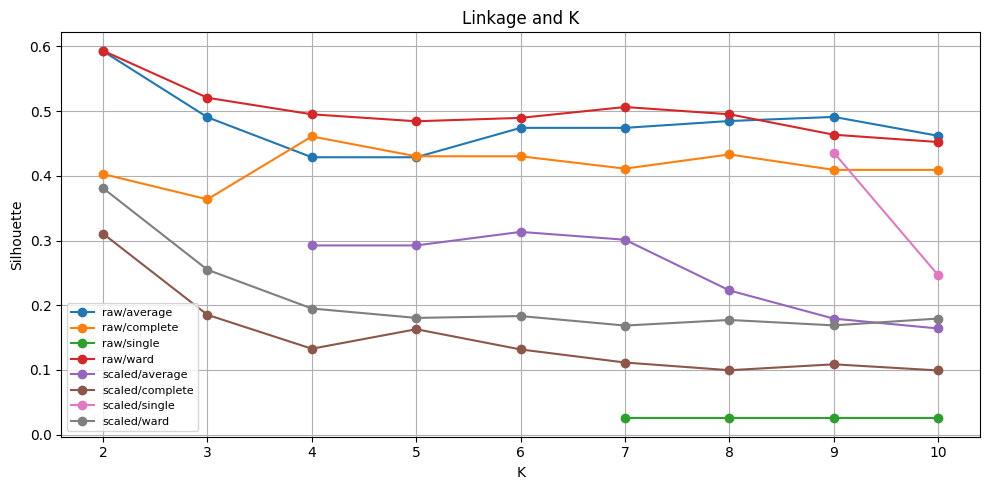

,scale,linkage,k,silhouette,db,min_size,sizes
0,raw,average,2,0.593,0.510,1280,"2530, 1280"
1,raw,complete,4,0.461,0.581,362,"879, 1822, 362, 747"
2,raw,single,8,0.025,0.364,1,"3802, 2, 1, 1, 1, 1, 1, 1"
3,raw,ward,2,0.593,0.511,1300,"2510, 1300"
4,scaled,average,6,0.313,0.836,2,"46, 1992, 1761, 2, 2, 7"
5,scaled,complete,2,0.311,1.145,1387,"2423, 1387"
6,scaled,single,9,0.436,0.449,1,"3800, 3, 1, 1, 1, 1, 1, 1, 1"
7,scaled,ward,2,0.381,0.966,1483,"2327, 1483"


**Cách đọc output linkage:** bảng rút gọn lấy silhouette cao nhất trong từng cặp scale/linkage. Nếu silhouette cao nhưng `min_size` chỉ 1–2, điểm số có thể phản ánh một cụm lớn rất gọn theo metric cùng vài singleton, chứ không phải phân hoạch hữu ích. Đường single thường đứt quãng hoặc có điểm không tính được vì mẫu silhouette 1.000 hàng không chứa singleton hiếm; đó chính là dấu hiệu chaining cần đọc cùng `sizes`. Ward/average raw nổi bật ở K=2 cho thấy tín hiệu kích thước mạnh cũng chi phối phân cụm phân cấp, nhất quán với K-means.

In [4]:
rows = []
partitions = {}
for scale, X in matrices.items():
    for link in ['single', 'complete', 'average', 'ward']:
        for k in KS:
            model = AgglomerativeClustering(n_clusters=k, linkage=link, metric='euclidean')
            start = perf_counter()
            labels = model.fit_predict(X)
            runtime = (perf_counter() - start) * 1000
            if len(np.unique(labels[sample_idx])) < 2:
                # Fixed metric sample misses tiny clusters; do not invent a silhouette score.
                metrics = {'silhouette': np.nan,
                           'ch': calinski_harabasz_score(X, labels),
                           'db': davies_bouldin_score(X, labels)}
            else:
                metrics = quality(X, labels)
            rows.append({'scale': scale, 'linkage': link, 'k': k, **metrics,
                         'sizes': sizes(labels), 'min_size': np.bincount(labels).min(),
                         'runtime_ms': runtime})
            partitions[(scale, link, k)] = labels
grid = pd.DataFrame(rows)
display(grid.round(3))
fig, ax = plt.subplots(figsize=(10, 5))
for (scale, link), part in grid.groupby(['scale', 'linkage']):
    ax.plot(part.k, part.silhouette, marker='o', label=f'{scale}/{link}')
ax.set(xlabel='K', ylabel='Silhouette', title='Linkage and K')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
best_by_family = (grid.dropna(subset=['silhouette'])
                  .sort_values('silhouette', ascending=False)
                  .groupby(['scale', 'linkage'], as_index=False).first()
                  [['scale', 'linkage', 'k', 'silhouette', 'db', 'min_size', 'sizes']])
display(best_by_family.round(3))
display(Markdown(
    '**Cách đọc output linkage:** bảng rút gọn lấy silhouette cao nhất trong từng cặp scale/linkage. '
    'Nếu silhouette cao nhưng `min_size` chỉ 1–2, điểm số có thể phản ánh một cụm lớn rất gọn theo '
    'metric cùng vài singleton, chứ không phải phân hoạch hữu ích. Đường single thường đứt quãng hoặc '
    'có điểm không tính được vì mẫu silhouette 1.000 hàng không chứa singleton hiếm; đó chính là dấu hiệu '
    'chaining cần đọc cùng `sizes`. Ward/average raw nổi bật ở K=2 cho thấy tín hiệu kích thước mạnh '
    'cũng chi phối phân cụm phân cấp, nhất quán với K-means.'))

In [5]:
eligible = grid[(grid.min_size >= int(np.ceil(.01 * len(X_raw)))) & grid.silhouette.notna()]
assert not eligible.empty
shortlist = eligible[eligible.silhouette >= eligible.silhouette.max() - .01]
selected = shortlist.sort_values(['k', 'db', 'runtime_ms']).iloc[0]
scale, link, k = str(selected['scale']), str(selected['linkage']), int(selected['k'])
X = matrices[scale]
chosen_h = partitions[(scale, link, k)]
display(shortlist.round(3))
selected_counts = np.bincount(chosen_h)
display(Markdown(
    f'**Vì sao chọn `{scale}/{link}`, K={k}:** silhouette={selected.silhouette:.3f}, '
    f'DB={selected.db:.3f}, cụm nhỏ nhất={int(selected.min_size)} và tỷ lệ cụm nhỏ/lớn '
    f'{selected_counts.min()/selected_counts.max():.3f}. Average và Ward raw K=2 nằm trong cùng tie band; '
    'quy tắc DB/runtime của bài hierarchical phá hòa theo dữ liệu đo. Điều quan trọng hơn tên linkage là '
    'cả hai đều tạo hai nhóm lớn, trái với single tạo cụm đơn lẻ. Cấu hình được chốt hoàn toàn bằng '
    'metric nội tại; chưa xem Cammeo/Osmancik.'))

,scale,linkage,k,silhouette,ch,db,sizes,min_size,runtime_ms
18,raw,average,2,0.593,8367.957,0.510,"2530, 1280",1280,382.103
27,raw,ward,2,0.593,8442.296,0.511,"2510, 1300",1300,383.797


**Vì sao chọn `raw/average`, K=2:** silhouette=0.593, DB=0.510, cụm nhỏ nhất=1280 và tỷ lệ cụm nhỏ/lớn 0.506. Average và Ward raw K=2 nằm trong cùng tie band; quy tắc DB/runtime của bài hierarchical phá hòa theo dữ liệu đo. Điều quan trọng hơn tên linkage là cả hai đều tạo hai nhóm lớn, trái với single tạo cụm đơn lẻ. Cấu hình được chốt hoàn toàn bằng metric nội tại; chưa xem Cammeo/Osmancik.

## 2. Dendrogram Ward và average

Cùng 1.000 index đã chọn cho silhouette, lấy hai cây bằng SciPy. Subset chỉ phục vụ đọc hình, không thay kết quả trên 3.810 hàng. Height của Ward là khoảng cách Ward khi gộp, không phải khoảng cách cặp điểm thông thường.

ward cut height: 67214.759 last merge: 88855.419
average cut height: 3469.222 last merge: 4009.739


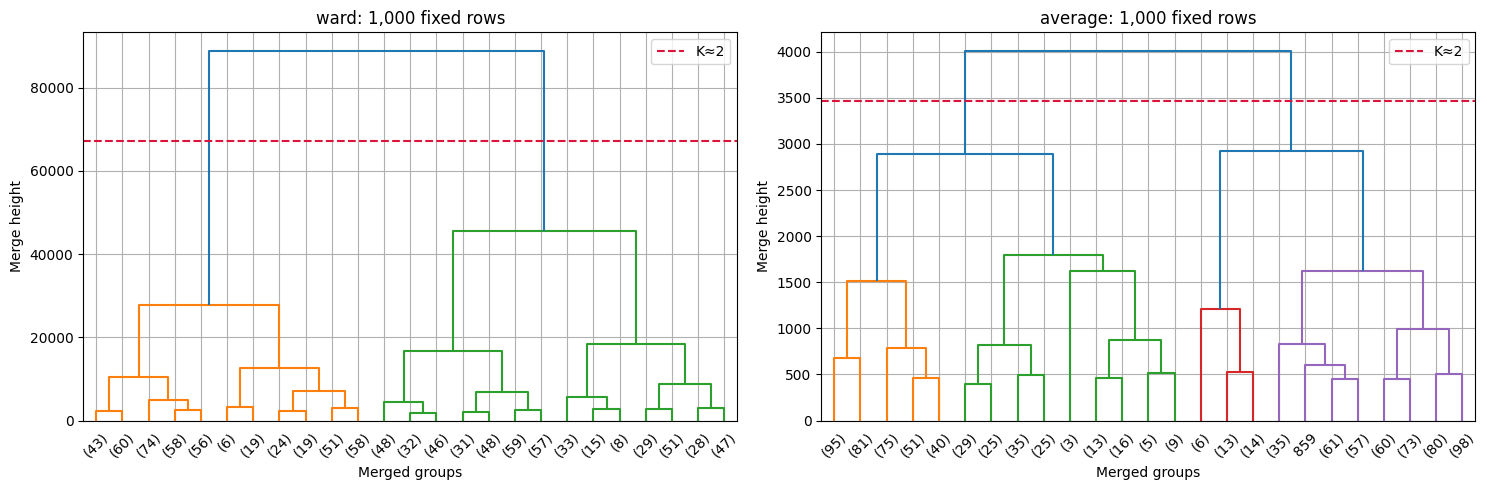

Subset size: 1000 first indices: [16 17 19 20 21 23 27 30 43 44]


**Đọc merge height:** với Ward, lần gộp cuối ở 88855.4, cao hơn lần áp chót 45574.1; với average là 4009.7 so với 2928.7. Khoảng nhảy gần đỉnh cho biết để ép từ hai nhánh lớn xuống một cụm cần chấp nhận một phép gộp xa hơn các phép trước. Đường đỏ nằm giữa hai mức gộp quanh K=2, nhưng không phải ngưỡng xác suất hay kiểm định thống kê. Giá trị Ward lớn hơn average do công thức linkage khác, nên chỉ so chiều cao trong cùng một dendrogram.

In [6]:
from scipy.cluster.hierarchy import linkage, dendrogram

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dendrogram_stats = {}
for axis, rule in zip(axes, ['ward', 'average']):
    tree = linkage(X[sample_idx], method=rule, metric='euclidean')
    dendrogram(tree, truncate_mode='lastp', p=25, show_leaf_counts=True, ax=axis)
    cut_height = (tree[-k, 2] + tree[-k + 1, 2]) / 2
    axis.axhline(cut_height, color='crimson', ls='--', label=f'K≈{k}')
    axis.set(title=f'{rule}: 1,000 fixed rows', xlabel='Merged groups', ylabel='Merge height')
    axis.legend()
    dendrogram_stats[rule] = {'cut': cut_height, 'last': tree[-1, 2],
                              'previous': tree[-2, 2]}
    print(rule, 'cut height:', round(cut_height, 3), 'last merge:', round(tree[-1, 2], 3))
plt.tight_layout(); plt.show()
print('Subset size:', len(sample_idx), 'first indices:', sample_idx[:10])
display(Markdown(
    f'**Đọc merge height:** với Ward, lần gộp cuối ở {dendrogram_stats["ward"]["last"]:.1f}, '
    f'cao hơn lần áp chót {dendrogram_stats["ward"]["previous"]:.1f}; với average là '
    f'{dendrogram_stats["average"]["last"]:.1f} so với '
    f'{dendrogram_stats["average"]["previous"]:.1f}. Khoảng nhảy gần đỉnh cho biết để ép từ hai '
    'nhánh lớn xuống một cụm cần chấp nhận một phép gộp xa hơn các phép trước. Đường đỏ nằm giữa hai '
    'mức gộp quanh K=2, nhưng không phải ngưỡng xác suất hay kiểm định thống kê. Giá trị Ward lớn hơn '
    'average do công thức linkage khác, nên chỉ so chiều cao trong cùng một dendrogram.'))

Đường cắt nằm giữa hai lần gộp quanh $K$ đã chọn từ metric. Bước nhảy height lớn gần đỉnh gợi ý các nhóm xa nhau theo từng linkage. Không suy ra số cụm toàn bộ dữ liệu chỉ từ dendrogram subset.

## 3. Bảng so sánh với K-means

Chọn ứng viên tốt nhất cho từng linkage trong cùng `scale`; nếu single không đạt ngưỡng 1%, vẫn hiển thị cấu hình tốt nhất kèm cờ `eligible=False`. K-means chạy cùng không gian và $K$ với cấu hình hierarchical đã chọn. Inertia không đưa vào bảng vì không phải objective của phân cụm phân cấp. `runtime_median_ms` là median ba lần fit sau một lần khởi động mỗi cấu hình; `runtime_ms` là lần fit của grid.

In [7]:
comparison_rows = []
best_labels = {}
for rule in ['single', 'complete', 'average', 'ward']:
    part = grid[(grid.scale == scale) & (grid.linkage == rule) & grid.silhouette.notna()]
    valid = part[part.min_size >= int(np.ceil(.01 * len(X_raw)))]
    eligible_rule = not valid.empty
    if eligible_rule:
        part = valid
    top = part.silhouette.max()
    row = part[part.silhouette >= top - .01].sort_values(['k', 'db']).iloc[0]
    comparison_rows.append({'method': rule, 'scale': scale, 'k': int(row.k),
                            'silhouette': row.silhouette, 'ch': row.ch, 'db': row.db,
                            'sizes': row.sizes, 'min_size': row.min_size,
                            'runtime_ms': row.runtime_ms, 'eligible': eligible_rule})
    best_labels[rule] = partitions[(scale, rule, int(row.k))]
baseline = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED)
start = perf_counter()
k_labels = baseline.fit_predict(X)
runtime = (perf_counter() - start) * 1000
comparison_rows.append({'method': 'K-means', 'scale': scale, 'k': k, **quality(X, k_labels),
                        'sizes': sizes(k_labels), 'min_size': np.bincount(k_labels).min(),
                        'runtime_ms': runtime,
                        'eligible': np.bincount(k_labels).min() >= int(np.ceil(.01 * len(X_raw)))})
comparison = pd.DataFrame(comparison_rows)
# Warm each estimator, then use median fit time to reduce startup noise.
medians = []
for row in comparison.itertuples():
    def make_estimator():
        if row.method == 'K-means':
            return KMeans(n_clusters=row.k, init='k-means++', n_init=20, random_state=SEED)
        return AgglomerativeClustering(n_clusters=row.k, linkage=row.method, metric='euclidean')
    make_estimator().fit(X)
    trials = []
    for _ in range(3):
        start = perf_counter()
        make_estimator().fit(X)
        trials.append((perf_counter() - start) * 1000)
    medians.append(float(np.median(trials)))
comparison['runtime_median_ms'] = medians
display(comparison.round(3))
valid_comparison = comparison[comparison.eligible]
best_sil = valid_comparison.loc[valid_comparison.silhouette.idxmax()]
fastest = valid_comparison.loc[valid_comparison.runtime_median_ms.idxmin()]
single_row = comparison[comparison.method == 'single'].iloc[0]
display(Markdown(
    f'**Giải thích bảng so sánh:** single có DB={single_row.db:.3f} nhìn có vẻ tốt, nhưng cụm nhỏ nhất '
    f'chỉ {int(single_row.min_size)} mẫu nên bị loại bởi tiêu chí đã công bố. Đây là ví dụ metric đơn lẻ '
    f'có thể gây hiểu sai. Trong các phương pháp hợp lệ, `{best_sil.method}` có silhouette cao nhất '
    f'({best_sil.silhouette:.3f}); `{fastest.method}` có median fit time thấp nhất '
    f'({fastest.runtime_median_ms:.1f} ms). CH cao hơn của K-means cho biết tỷ lệ phân tán giữa cụm/'
    'trong cụm lớn hơn, còn DB hơi cao hơn average/Ward cho thấy độ gọn tương đối không thắng ở mọi '
    'cách đo. Vì silhouette của ba ứng viên K=2 chênh dưới 0.01, runtime và tính tiện dụng trở thành '
    'tiêu chí phá hòa hợp lý, không phải bằng chứng K-means vượt trội tuyệt đối.'))

D:\miniconda3\envs\ai-algorithms\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\miniconda3\envs\ai-algorithms\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\miniconda3\envs\ai-algorithms\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "D:\miniconda3\envs\ai-algorithms\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^

,method,scale,k,silhouette,ch,db,sizes,min_size,runtime_ms,eligible,runtime_median_ms
0,single,raw,7,0.025,11.245,0.380,"2, 2, 3802, 1, 1, 1, 1",1,154.971,False,155.901
1,complete,raw,4,0.461,9108.393,0.581,"879, 1822, 362, 747",362,355.592,True,355.106
2,average,raw,2,0.593,8367.957,0.510,"2530, 1280",1280,382.103,True,416.590
3,ward,raw,2,0.593,8442.296,0.511,"2510, 1300",1300,383.797,True,389.492
4,K-means,raw,2,0.596,8769.568,0.527,"2327, 1483",1483,1133.053,True,117.270


**Giải thích bảng so sánh:** single có DB=0.380 nhìn có vẻ tốt, nhưng cụm nhỏ nhất chỉ 1 mẫu nên bị loại bởi tiêu chí đã công bố. Đây là ví dụ metric đơn lẻ có thể gây hiểu sai. Trong các phương pháp hợp lệ, `K-means` có silhouette cao nhất (0.596); `K-means` có median fit time thấp nhất (117.3 ms). CH cao hơn của K-means cho biết tỷ lệ phân tán giữa cụm/trong cụm lớn hơn, còn DB hơi cao hơn average/Ward cho thấy độ gọn tương đối không thắng ở mọi cách đo. Vì silhouette của ba ứng viên K=2 chênh dưới 0.01, runtime và tính tiện dụng trở thành tiêu chí phá hòa hợp lý, không phải bằng chứng K-means vượt trội tuyệt đối.

## 4. Outlier, hình dạng và runtime

Điểm cực trị được định nghĩa trước là 1% hàng xa median nhất trong không gian scaled. Đánh giá lại hai cấu hình đã chốt sau khi bỏ các hàng này; ARI và silhouette tính trên **cùng các hàng còn lại**. Đây là phân tích độ nhạy, không phải khẳng định các hàng bị bỏ là lỗi.

,method,sil_full_common,sil_without_common,ari_common,runtime_without_ms
0,K-means,0.5968,0.5955,0.9579,121.5465
1,average,0.5921,0.5921,1.0000,401.3520


Extreme rows: 39 common score rows: 994


**Đọc phép thử outlier:** bỏ 39 điểm cực trị làm K-means có ARI 0.9579; tức phần lớn quan hệ cùng cụm được giữ nhưng một vùng ranh giới thay đổi. `average` có ARI 1.0000, ổn định hơn trong phép thử cụ thể này. Silhouette K-means trên cùng 994 điểm đổi từ 0.5968 thành 0.5955; thay đổi nhỏ cho thấy outlier không quyết định chất lượng tổng thể, dù có thể làm vài điểm đổi phía. ARI=1 của hierarchical không có nghĩa thuật toán nói chung miễn nhiễm outlier; nó chỉ nói 39 điểm theo định nghĩa median-distance này không đổi cây cắt của các điểm còn lại.

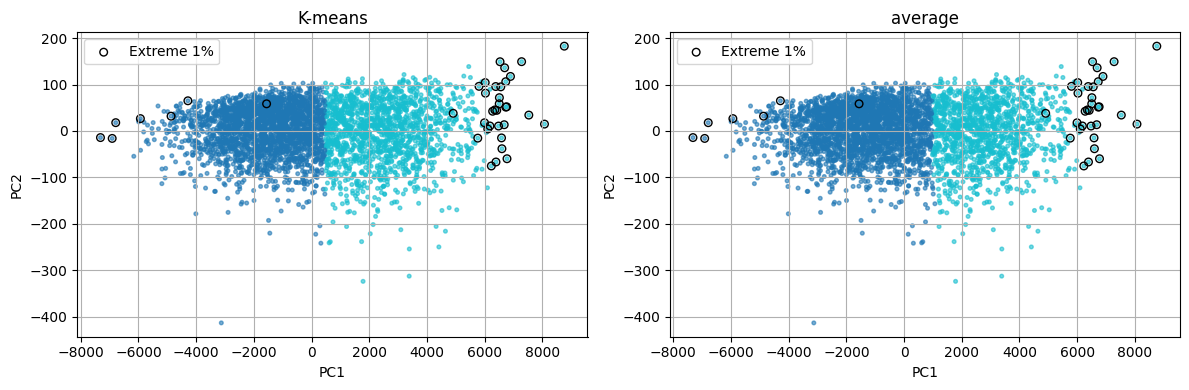

In [8]:
distance = np.linalg.norm(X_scaled - np.median(X_scaled, axis=0), axis=1)
extreme_count = int(np.ceil(.01 * len(X_scaled)))
extreme_idx = np.argsort(distance, kind='stable')[-extreme_count:]
keep = np.ones(len(X), dtype=bool); keep[extreme_idx] = False
common = sample_idx[keep[sample_idx]]
assert len(common) > 100

def sensitivity(method: str, before: np.ndarray, rule: str | None) -> dict[str, float | str]:
    estimator = (KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED)
                 if rule is None else AgglomerativeClustering(n_clusters=k, linkage=rule, metric='euclidean'))
    start = perf_counter()
    after = estimator.fit_predict(X[keep])
    elapsed = (perf_counter() - start) * 1000
    mapped = after[np.searchsorted(np.flatnonzero(keep), common)]
    return {'method': method,
            'sil_full_common': silhouette_score(X[common], before[common]),
            'sil_without_common': silhouette_score(X[common], mapped),
            'ari_common': adjusted_rand_score(before[keep], after),
            'runtime_without_ms': elapsed}

sensitivity_table = pd.DataFrame([sensitivity('K-means', k_labels, None),
                                  sensitivity(link, chosen_h, link)])
display(sensitivity_table.round(4))
print('Extreme rows:', extreme_count, 'common score rows:', len(common))
k_sens = sensitivity_table[sensitivity_table.method == 'K-means'].iloc[0]
h_sens = sensitivity_table[sensitivity_table.method == link].iloc[0]
display(Markdown(
    f'**Đọc phép thử outlier:** bỏ {extreme_count} điểm cực trị làm K-means có ARI '
    f'{k_sens.ari_common:.4f}; tức phần lớn quan hệ cùng cụm được giữ nhưng một vùng ranh giới thay đổi. '
    f'`{link}` có ARI {h_sens.ari_common:.4f}, ổn định hơn trong phép thử cụ thể này. Silhouette K-means '
    f'trên cùng {len(common)} điểm đổi từ {k_sens.sil_full_common:.4f} thành '
    f'{k_sens.sil_without_common:.4f}; thay đổi nhỏ cho thấy outlier không quyết định chất lượng tổng thể, '
    'dù có thể làm vài điểm đổi phía. ARI=1 của hierarchical không có nghĩa thuật toán nói chung miễn '
    'nhiễm outlier; nó chỉ nói 39 điểm theo định nghĩa median-distance này không đổi cây cắt của các điểm còn lại.'))
coords = PCA(n_components=2, random_state=SEED).fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, (method, labels) in zip(axes, [('K-means', k_labels), (link, chosen_h)]):
    axis.scatter(coords[:, 0], coords[:, 1], c=labels, s=7, cmap='tab10', alpha=.6)
    axis.scatter(coords[extreme_idx, 0], coords[extreme_idx, 1], facecolors='none',
                 edgecolors='black', s=30, label='Extreme 1%')
    axis.set(title=method, xlabel='PC1', ylabel='PC2'); axis.legend()
plt.tight_layout(); plt.show()

## 5. Khuyến nghị, profile cụm và hậu kiểm

Quy tắc cuối: trong các phương pháp hợp lệ có silhouette cách cao nhất không quá 0.01, ưu tiên median runtime ba lần fit thấp hơn, rồi $K$ nhỏ hơn, rồi DB thấp hơn. Runtime trên một máy có nhiễu; báo cáo cùng cluster sizes và độ nhạy outlier để người đọc đánh giá tradeoff. K-means thường có chi phí gần tuyến tính theo số hàng trong mỗi iteration; phân cụm phân cấp cần chi phí/bộ nhớ bậc hai trong trường hợp thông thường. PCA 2D chỉ minh họa, model dùng đủ 7 chiều.

In [9]:
feasible = comparison[comparison.eligible]
assert not feasible.empty
candidates = feasible[feasible.silhouette >= feasible.silhouette.max() - .01]
winner = candidates.sort_values(['runtime_median_ms', 'k', 'db']).iloc[0]
winner_name = str(winner.method)
winner_labels = k_labels if winner_name == 'K-means' else best_labels[winner_name]
display(candidates.round(3))
print('Recommended:', winner_name, 'K:', int(winner.k), 'scale:', scale,
      'silhouette:', round(winner.silhouette, 4))
profile = features.assign(cluster=winner_labels).groupby('cluster').agg(['count', 'median'])
display(profile.round(3))
medians_profile = features.assign(cluster=winner_labels).groupby('cluster').median()
area_gap = 100 * (medians_profile.Area.max() - medians_profile.Area.min()) / medians_profile.Area.min()
axis_gap = 100 * (medians_profile.Major_Axis_Length.max() - medians_profile.Major_Axis_Length.min()) / medians_profile.Major_Axis_Length.min()
display(Markdown(
    f'**Diễn giải profile:** `{winner_name}` được chọn từ metric không giám sát. Median Area của cụm lớn '
    f'cao hơn cụm nhỏ khoảng {area_gap:.1f}%, Major Axis cao hơn khoảng {axis_gap:.1f}%; Eccentricity '
    'chỉ chênh nhẹ. Vì raw Euclidean đặt trọng số ngầm lớn vào các biến kích thước tương quan, kết quả '
    'chủ yếu là phân tầng hạt nhỏ/lớn hơn là khám phá hai kiểu hình độc lập trên mọi chiều. `count` lặp '
    'dưới từng đặc trưng chỉ là số hàng của cụm do bảng multi-index của pandas, không phải số quan sát '
    'khác nhau cho từng biến. ID cụm không mang tên giống lúa.'))

,method,scale,k,silhouette,ch,db,sizes,min_size,runtime_ms,eligible,runtime_median_ms
2,average,raw,2,0.593,8367.957,0.510,"2530, 1280",1280,382.103,True,416.590
3,ward,raw,2,0.593,8442.296,0.511,"2510, 1300",1300,383.797,True,389.492
4,K-means,raw,2,0.596,8769.568,0.527,"2327, 1483",1483,1133.053,True,117.270


Recommended: K-means K: 2 scale: raw silhouette: 0.5958


Area          Perimeter          Major_Axis_Length           \
        count   median     count   median             count   median   
cluster                                                                
0        2327  11605.0      2327  430.631              2327  176.480   
1        1483  14369.0      1483  490.751              1483  206.776   

        Minor_Axis_Length         Eccentricity        Convex_Area           \
                    count  median        count median       count   median   
cluster                                                                      
0                    2327  83.924         2327  0.879        2327  11850.0   
1                    1483  90.245         1483  0.900        1483  14709.0   

        Extent         
         count median  
cluster                
0         2327  0.651  
1         1483  0.636

**Diễn giải profile:** `K-means` được chọn từ metric không giám sát. Median Area của cụm lớn cao hơn cụm nhỏ khoảng 23.8%, Major Axis cao hơn khoảng 17.2%; Eccentricity chỉ chênh nhẹ. Vì raw Euclidean đặt trọng số ngầm lớn vào các biến kích thước tương quan, kết quả chủ yếu là phân tầng hạt nhỏ/lớn hơn là khám phá hai kiểu hình độc lập trên mọi chiều. `count` lặp dưới từng đặc trưng chỉ là số hàng của cụm do bảng multi-index của pandas, không phải số quan sát khác nhau cho từng biến. ID cụm không mang tên giống lúa.

In [10]:
# Post-selection only: true labels have not influenced any configuration above.
codes = pd.Categorical(y_true).codes
post_ari = adjusted_rand_score(codes, winner_labels)
post_nmi = normalized_mutual_info_score(codes, winner_labels)
display(pd.crosstab(pd.Series(winner_labels, name='cluster'),
                    pd.Series(y_true, name='rice_variety')))
print(f'Post-selection ARI={post_ari:.4f}, NMI={post_nmi:.4f}')
contingency = pd.crosstab(pd.Series(winner_labels), pd.Series(y_true))
majority_accuracy = contingency.max(axis=1).sum() / contingency.to_numpy().sum()
display(Markdown(
    f'**Đọc hậu kiểm:** nếu gán tên giống cho mỗi cụm theo lớp chiếm đa số, độ khớp là '
    f'{majority_accuracy:.1%}; ARI={post_ari:.4f} đã hiệu chỉnh cho sự đồng thuận do ngẫu nhiên, còn '
    f'NMI={post_nmi:.4f} đo lượng thông tin nhãn được chia sẻ. Các giá trị trung bình cho thấy hai cụm '
    'liên quan đáng kể nhưng không trùng hoàn toàn với hai giống: hình thái kích thước chỉ giải thích một '
    'phần nhãn. Vì nhãn chỉ được mở sau khi chọn, đây là đánh giá hậu kiểm chứ không phải tối ưu có giám sát. '
    '**Giới hạn:** kết quả gắn với Rice, Euclidean, grid K=2..10, quy tắc cụm tối thiểu 1%, và mẫu '
    '1.000 hàng cho silhouette/dendrogram; mức khớp nhãn không tự chứng minh tính hữu ích nghiệp vụ.'))

rice_variety,Cammeo,Osmancik
cluster,,
0,302,2025
1,1328,155


Post-selection ARI=0.5772, NMI=0.4687


**Đọc hậu kiểm:** nếu gán tên giống cho mỗi cụm theo lớp chiếm đa số, độ khớp là 88.0%; ARI=0.5772 đã hiệu chỉnh cho sự đồng thuận do ngẫu nhiên, còn NMI=0.4687 đo lượng thông tin nhãn được chia sẻ. Các giá trị trung bình cho thấy hai cụm liên quan đáng kể nhưng không trùng hoàn toàn với hai giống: hình thái kích thước chỉ giải thích một phần nhãn. Vì nhãn chỉ được mở sau khi chọn, đây là đánh giá hậu kiểm chứ không phải tối ưu có giám sát. **Giới hạn:** kết quả gắn với Rice, Euclidean, grid K=2..10, quy tắc cụm tối thiểu 1%, và mẫu 1.000 hàng cho silhouette/dendrogram; mức khớp nhãn không tự chứng minh tính hữu ích nghiệp vụ.